### **Title: DSC670-T301 Advanced Uses of Generative AI (2271-1)**

#### **Professor:** *Frank Neugebauer*

#### **Date:** *31 Oct 2026*

#### **Author:** *Akhil Anand Thazhaniyil Muralidharan*

#### **Description:** Milestone 3: Full-Parameter Fine-Tuning of a Hugging Face Model for Telecom Plan Selection and Billing Assistance



*************

### Abstract

Milestone 2 found that structured prompts improved clarity but did not consistently prevent invented plan features or incorrect billing explanations. Following the revised assignment guidance, this milestone performs full-parameter supervised fine-tuning of the open-weight `Qwen/Qwen2.5-0.5B-Instruct` model from Hugging Face in a GPU-enabled Google Colab runtime. The notebook builds and validates a privacy-safe telecom dataset, trains and validates all model parameters, records local training metrics, saves the complete model, and compares the base and fine-tuned models on five held-out scenarios. The evaluation retains groundedness, relevance, clarity, completeness, and safety.



********

### Problem Statement and Thought Process
The assistant must respect budgets and usage constraints, explain only supplied billing facts, request missing information, and avoid inventing fees, promotions, account events, or guarantees. Fine-tuning is used to teach a stable response behavior, not to memorize changing prices. Expected sections are: customer need, recommendation or explanation, evidence, tradeoff or uncertainty, and next step.

*****

### Full Fine-Tuning, Not LoRA

* No PEFT library, adapters, frozen weights, LoRA rank, or LoRA alpha are used.

* Every parameter in `Qwen/Qwen2.5-0.5B-Instruct` is explicitly marked trainable and verified before training.

* The complete tokenizer and model weights are saved locally after training.

* Evidence is preserved through parameter counts, Trainer history, loss metrics, saved checkpoints, and held-out responses.



****

### Dataset Selection and Why I Chose It

I selected the Hugging Face dataset **`akshayjambhulkar/customer-support-telecom-alpaca`** because it is directly related to the domain of my project. Its records are written as telecom customer questions and support responses, so the subject matter is closer to plan selection, billing, devices, roaming, coverage, and service support than a general question-answering dataset. This domain alignment makes it useful for identifying realistic customer wording and common support intents.

The dataset was not chosen because it is large enough to represent the entire telecom industry. It is a small seed dataset, and that is an important limitation. I chose it because it offers three practical advantages for this milestone:

1. **Domain relevance.** The questions use telecom terminology and customer-support language rather than unrelated topics.
2. **Simple structure.** The instruction and output fields can be converted into the chat-message JSONL format needed for supervised fine-tuning.
3. **Privacy protection.** The public examples do not require me to use proprietary customer transcripts, account numbers, names, addresses, or internal company policies.

I did not copy every public response directly into the training file. Some public responses may state that a feature is supported or that a fee may apply even when no provider, plan, location, or policy was supplied. That behavior conflicts with the central requirement from Milestone 2: the assistant must use only verified facts in the prompt. I therefore use selected public **questions as scenario seeds** and rewrite the target answers so that the assistant asks for verification when provider-specific evidence is missing.

The public subset is combined with synthetic examples for plan recommendation, confirmed billing changes, and insufficient-information cases. The synthetic records let me control the facts and expected answers precisely. This hybrid approach gives me domain language from a public source while preserving the grounded response behavior that the project is trying to teach.

### Dataset Limitations

The dataset is not a substitute for production telecom data. It is small, may not represent every customer communication style, and does not contain a verified catalog of current plans or policies. The synthetic examples are also cleaner than real conversations. For these reasons, I use a held-out evaluation set and do not claim that good notebook results would automatically translate to production readiness.

*****

In [65]:
!pip -q install "transformers>=4.46.0" "datasets>=3.0.0" "accelerate>=1.0.0" pandas matplotlib scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [66]:
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, re
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset, Dataset
from sklearn.model_selection import train_test_split
from transformers import AutoModelForCausalLM, AutoTokenizer, DataCollatorForSeq2Seq, Trainer, TrainingArguments, set_seed



OUTPUT_DIR=Path("milestone3_outputs"); OUTPUT_DIR.mkdir(exist_ok=True)
SYSTEM_PROMPT="""You are a telecom plan and billing assistant. Use only facts explicitly supplied by the user. Do not invent prices, fees, promotions, taxes, policies, account activity, availability, or guarantees. If information is insufficient, ask concise follow-up questions. Use headings: Customer need; Recommendation or explanation; Evidence; Tradeoff or uncertainty; Next step."""
SEED=42; set_seed(SEED)

### Load and Inspect the Public Dataset
The public data is used only as a scenario seed. Samples are displayed for human review before any training file is created.

In [67]:
PUBLIC_DATASET="akshayjambhulkar/customer-support-telecom-alpaca"
public_df=load_dataset(PUBLIC_DATASET,split="train").to_pandas()
print("Rows:",len(public_df),"Columns:",list(public_df.columns)); display(public_df.head())

Rows: 116 Columns: ['instruction', 'input', 'output']


,instruction,input,output
0,Can I use my mobile plan while traveling abroad?,,"Yes, you can use your mobile plan while travel..."
1,What is VoLTE and do you support it?,,"VoLTE stands for Voice over LTE, which allows ..."
2,How can I check network coverage in my area?,,You can check network coverage in your area by...
3,What should I do if I lose my phone?,,"If you lose your phone, contact us immediately..."
4,How do I report a network issue?,,You can report a network issue by contacting o...


### Prompt and Response-Template Design

The prompt design continues the main lesson from Milestone 2. The earlier experiments showed that a lightweight model could produce fluent answers while still inventing plan features or misunderstanding a confirmed billing fact. A longer prompt alone did not reliably solve that issue. For Milestone 3, the prompt is therefore designed to make the evidence boundary explicit and to teach the same boundary repeatedly through supervised examples.

*****

### Why I Chose the System Prompt

The system prompt tells the model to use only facts supplied by the user and explicitly prohibits invented prices, fees, promotions, taxes, policies, account activity, availability, and guarantees. I included these categories because they are the most consequential failure types for this project. A fabricated speed recommendation is inconvenient, but a fabricated charge, discount, account event, or guarantee can directly mislead a customer.

The prompt also tells the model to ask concise follow-up questions when details are missing. This is intentional. In a plan-selection scenario, device count, usage pattern, budget, current plan, and available plan options can change the recommendation. In a billing scenario, the assistant needs actual line items before it can explain a change. Asking for evidence is safer than producing a confident guess.

*****

### Why I Chose the Five-Part Response Structure

The required headings create a repeatable reasoning and communication pattern:

- **Customer need** checks whether the assistant understood the request.
- **Recommendation or explanation** gives the direct answer when evidence supports one.
- **Evidence** links the answer to supplied facts.
- **Tradeoff or uncertainty** prevents the response from hiding missing information.
- **Next step** gives the customer a useful and safe action.

This structure is not intended to make every answer longer. It is intended to make the answer auditable. During evaluation, I can inspect whether the model used the correct facts, disclosed uncertainty, and avoided unsupported details.

****
### Why the Training Prompts Vary

The generated examples change budgets, device counts, speeds, usage patterns, billing amounts, and confirmed causes. Variation reduces the chance that the model merely memorizes one exact sentence. At the same time, the response structure stays stable so the model can learn the desired behavior. The held-out prompts use different plan names and wording to test whether the learned pattern generalizes beyond the training records.

****

### Build the Training Corpus and Expected Behavior
The synthetic examples vary device counts, budgets, speeds, billing causes, and missing-information cases. Each expected response is derived only from facts in its user message. Public questions are included with rewritten targets that request provider verification rather than making unsupported claims.

### How the Examples Support the Project Goal

The plan examples teach budget filtering and evidence-based selection. The billing examples teach the model to connect a known bill difference to the one confirmed line item instead of listing unrelated possibilities. The missing-information examples teach the model to pause and request facts. The rewritten public-question examples teach conservative handling of provider-specific questions.

The target answers are intentionally consistent. Full fine-tuning updates the model using repeated input-output patterns, so inconsistent target wording would make the desired behavior harder to learn. Consistency here refers to structure and safety behavior, not identical customer scenarios.


In [68]:
def ex(user,answer,source): return {"messages":[{"role":"system","content":SYSTEM_PROMPT},{"role":"user","content":user},{"role":"assistant","content":answer}],"source":source}
rows=[]; plans=[("Connect 150",40,150,10),("Work 400",65,400,40),("Gig 900",90,900,90)]
for i in range(24):
 devices=3+i%10; budget=[50,70,95][i%3]; remote=i%2==0
 catalog="; ".join(f"{n} costs ${p} with {d} Mbps download and {u} Mbps upload" for n,p,d,u in plans)
 user=f"Available plans: {catalog}. Customer uses {devices} devices, {'works remotely with daily video calls' if remote else 'mainly streams and browses'}, and has a maximum budget of ${budget}. Recommend one eligible plan and one tradeoff using only these facts."
 chosen=[p for p in plans if p[1]<=budget][-1]; n,p,d,u=chosen
 ans=f"""Customer need
The customer has {devices} devices within a ${budget} budget.

Recommendation or explanation
{n} is the strongest eligible supplied option.

Evidence
It costs ${p} and provides {d} Mbps download and {u} Mbps upload.

Tradeoff or uncertainty
Data allowance, equipment, tax, and promotion details were not supplied.

Next step
Confirm unlisted terms before changing service."""
 rows.append(ex(user,ans,"synthetic_plan"))
cases=[(80,100,"a $20 promotional credit ended"),(95,107,"a $12 equipment charge was added"),(110,100,"a one-time $10 credit was applied"),(70,78,"an $8 late fee appears")]
for i in range(20):
 old,new,fact=cases[i%4]; diff=abs(new-old); direction="increase" if new>old else "decrease"
 user=f"A bill changed from ${old} to ${new}. The bill shows that {fact}. No other charge changed. Explain it and give one next step."
 ans=f"""Customer need
The customer wants to understand the bill change.

Recommendation or explanation
The ${diff} {direction} is explained by the listed item.

Evidence
The bill states that {fact} and no other charge changed.

Tradeoff or uncertainty
No additional cause is supported.

Next step
Review the line item and contact billing support if it is unexpected."""
 rows.append(ex(user,ans,"synthetic_billing"))
missing=["My internet is slow. Tell me exactly which plan to buy.","Why is my bill higher?","Should I upgrade?","Am I eligible for a promotion?","Guarantee a faster plan fixes Wi-Fi."]
for i in range(16):
 ans="""Customer need
Guidance is requested, but verified facts are missing.

Recommendation or explanation
A specific answer cannot be confirmed.

Evidence
No current plan, available options, usage, budget, or bill facts were supplied.

Tradeoff or uncertainty
Guessing could create an unsupported answer.

Next step
Provide the relevant plan or bill facts, device count, usage needs, and budget."""
 rows.append(ex(missing[i%5],ans,"synthetic_missing"))
kw=re.compile(r"bill|plan|data|roam|network|device|internet|charge|payment|upgrade|coverage",re.I)
subset=public_df[public_df.instruction.astype(str).str.contains(kw,na=False)].head(20)
for _,r in subset.iterrows():
 user=f"Public telecom question: {r.instruction} No provider-specific facts were supplied."
 ans="""Customer need
The customer has a telecom question.

Recommendation or explanation
A provider-specific answer cannot be confirmed.

Evidence
No verified plan terms, fee schedule, coverage result, or policy was supplied.

Tradeoff or uncertainty
Availability and charges vary by provider, plan, device, and location.

Next step
Check current approved provider documentation or contact support."""
 rows.append(ex(user,ans,"public_rewritten"))
print("Total examples:",len(rows),"Public rewritten:",len(subset))

Total examples: 80 Public rewritten: 20


### Dataset Visualizations and Interpretation

The following charts describe the dataset before training. They do not claim model quality. Their purpose is to verify that the corpus includes multiple task types and to identify unusually long examples that could increase cost or be truncated.

The first chart shows how many records come from plan recommendations, billing explanations, missing-information cases, and rewritten public questions. A severe imbalance could cause the model to overlearn one response type. The second chart compares user-prompt and assistant-response lengths. This helps confirm that the targets are detailed enough to demonstrate the five-part structure without becoming unnecessarily long.

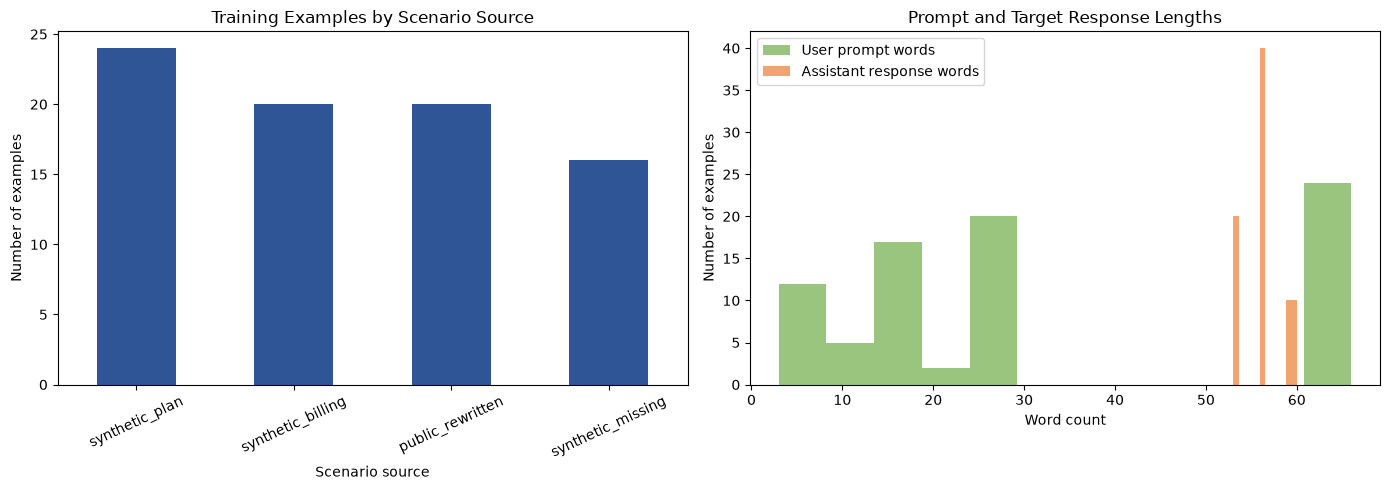

user_words               assistant_words              
                       count  mean min max           count  mean min max
source                                                                  
public_rewritten          20  16.5  13  20              20  53.0  53  53
synthetic_billing         20  27.5  27  28              20  59.5  59  60
synthetic_missing         16   6.5   3  11              16  56.0  56  56
synthetic_plan            24  65.0  64  66              24  56.0  56  56

In [69]:
dataset_audit=[]
for r in rows:
    user_text=next(m["content"] for m in r["messages"] if m["role"]=="user")
    assistant_text=next(m["content"] for m in r["messages"] if m["role"]=="assistant")
    dataset_audit.append({"source":r["source"],"user_words":len(user_text.split()),"assistant_words":len(assistant_text.split())})
audit_df=pd.DataFrame(dataset_audit)
fig,ax=plt.subplots(1,2,figsize=(14,5))
audit_df["source"].value_counts().plot(kind="bar",ax=ax[0],color="#2F5597")
ax[0].set(title="Training Examples by Scenario Source",xlabel="Scenario source",ylabel="Number of examples")
ax[0].tick_params(axis="x",rotation=25)
ax[1].hist(audit_df["user_words"],bins=12,alpha=.7,label="User prompt words",color="#70AD47")
ax[1].hist(audit_df["assistant_words"],bins=12,alpha=.7,label="Assistant response words",color="#ED7D31")
ax[1].set(title="Prompt and Target Response Lengths",xlabel="Word count",ylabel="Number of examples")
ax[1].legend(); plt.tight_layout(); plt.show()
display(audit_df.groupby("source")[["user_words","assistant_words"]].agg(["count","mean","min","max"]).round(1))

**How I interpret these charts:** 

* The source chart confirms whether all four intended behaviors are represented. 
* The length chart helps me look for extreme records before upload. 
* A narrow response-length range is expected because the target answers use the same five-part structure. 
* If one source dominates or a few records are much longer than the others, I would rebalance or shorten the corpus before creating the job.

### Validate, Split, and Version the Dataset
Validation checks roles, empty content, assistant targets, duplicates, and split leakage. SHA-256 hashes provide evidence of the exact files submitted.

In [70]:
def validate(data):

 errors=[]; seen={}

 for i,r in enumerate(data):

  msgs=r.get("messages",[]); roles={m.get("role") for m in msgs}

  user=next((m.get("content","") for m in msgs if m.get("role")=="user"),"")

  if not msgs or not {"system","user","assistant"}.issubset(roles): errors.append((i,"structure"))

  if any(m.get("role") not in {"system","user","assistant"} or not str(m.get("content","")).strip() for m in msgs): errors.append((i,"message"))

  if user in seen: errors.append((i,"duplicate",seen[user]))

  else: seen[user]=i

 return errors



initial_errors=validate(rows)

blocking_errors=[e for e in initial_errors if e[1]!="duplicate"]

assert not blocking_errors,f"Dataset errors: {blocking_errors[:10]}"



seen_users=set(); unique_rows=[]

for r in rows:

 user=next(m["content"] for m in r["messages"] if m["role"]=="user")

 if user not in seen_users:

  unique_rows.append(r); seen_users.add(user)

removed_count=len(rows)-len(unique_rows); rows=unique_rows

print(f"Removed {removed_count} exact duplicate prompts; {len(rows)} unique examples remain.")



errors=validate(rows); print(errors[:10],"count",len(errors)); assert not errors

train,valid=train_test_split(rows,test_size=.2,random_state=SEED,stratify=[r["source"] for r in rows])

def users(x): return {next(m["content"] for m in r["messages"] if m["role"]=="user") for r in x}

assert users(train).isdisjoint(users(valid)); print(len(train),len(valid))

Removed 27 exact duplicate prompts; 53 unique examples remain.
[] count 0
42 11


In [71]:
def write_jsonl(data,path):
 with open(path,"w",encoding="utf-8") as f:
  for r in data: f.write(json.dumps({"messages":r["messages"]},ensure_ascii=False)+"\n")
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
train_path=OUTPUT_DIR/"telecom_train.jsonl"; valid_path=OUTPUT_DIR/"telecom_validation.jsonl"
write_jsonl(train,train_path); write_jsonl(valid,valid_path)
manifest={"created_utc":datetime.now(timezone.utc).isoformat(),"public_dataset":PUBLIC_DATASET,"train_rows":len(train),"validation_rows":len(valid),"train_sha256":sha(train_path),"validation_sha256":sha(valid_path)}
(OUTPUT_DIR/"dataset_manifest.json").write_text(json.dumps(manifest,indent=2)); display(pd.DataFrame([manifest]))

,created_utc,public_dataset,train_rows,validation_rows,train_sha256,validation_sha256
0,2026-11-01T04:39:45.561801+00:00,akshayjambhulkar/customer-support-telecom-alpaca,42,11,4fe0e81d8c202f2b03b690110d9b0cd5400e05a1f224e9...,7b429bd3d79588b55ba6e1759cb24da0068ab21aff2c37...


### Hugging Face Model and Colab GPU

The notebook uses the open-weight `Qwen/Qwen2.5-0.5B-Instruct` model. Its size makes full-parameter training practical on a Colab GPU while retaining an instruction-following chat interface. The runtime cell reports the detected device and warns when no GPU is available. No API key is required.

In [72]:
MODEL_NAME="Qwen/Qwen2.5-0.5B-Instruct"

MODEL_OUTPUT_DIR=OUTPUT_DIR/"qwen_full_finetune"

DEVICE="cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

if DEVICE=="cpu":

 print("WARNING: No GPU detected. In Colab select Runtime > Change runtime type > GPU, then restart and run all cells.")

else:

 print("Training device:",DEVICE)

if DEVICE=="cuda": print("GPU:",torch.cuda.get_device_name(0))



tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None: tokenizer.pad_token=tokenizer.eos_token

print("Hugging Face model:",MODEL_NAME)

Training device: mps
Hugging Face model: Qwen/Qwen2.5-0.5B-Instruct


### Approach Used Without LoRA



Milestone 2 proposed LoRA because it is practical for larger local models with limited GPU memory. The revised Milestone 3 guidance permits a Hugging Face model and asks for fine-tuning, so this notebook uses a small model whose complete parameter set can be updated on a Colab GPU.



### Where LoRA Is Not Used



* The notebook never imports `peft`, `LoraConfig`, `get_peft_model`, or adapter libraries.

* It does not configure a LoRA rank, alpha, dropout, or target modules.

* It does not quantize or freeze the base model before training.

* It asserts that the trainable parameter count equals the total parameter count.



### Full-Parameter Workflow



1. Build chat-formatted system, user, and assistant examples.

2. Validate and split the records into training and validation sets.

3. Apply Qwen's chat template and mask system/user tokens from the supervised loss.

4. Load the complete causal language model and make every parameter trainable.

5. Train locally with Hugging Face `Trainer`, mixed precision, and gradient checkpointing.

6. Save the complete model and tokenizer, not adapter weights.

7. Record training and validation loss from Trainer history.

8. Compare the untouched base model and full fine-tuned model on the same held-out prompts.



### Why This Approach Fits the Assignment



The approach follows the professor's revised guidance to use a Hugging Face model when managed OpenAI training is unavailable. A 0.5-billion-parameter model is intentionally selected so full training is feasible in Colab. The experiment remains auditable through dataset hashes, the 100% trainable-parameter assertion, local checkpoints, metric history, and held-out evaluation.



*******

### Create and Train the Model

These cells prepare assistant-only supervised labels and perform full-parameter training. Mixed precision and gradient checkpointing reduce Colab GPU memory use without introducing LoRA, adapters, or frozen layers.

In [73]:
MAX_LENGTH=512

def tokenize_example(record):

 messages=record["messages"]

 full_text=tokenizer.apply_chat_template(messages,tokenize=False,add_generation_prompt=False)

 prompt_text=tokenizer.apply_chat_template(messages[:-1],tokenize=False,add_generation_prompt=True)

 encoded=tokenizer(full_text,truncation=True,max_length=MAX_LENGTH)

 prompt_ids=tokenizer(prompt_text,truncation=True,max_length=MAX_LENGTH)["input_ids"]

 labels=encoded["input_ids"].copy(); prompt_length=min(len(prompt_ids),len(labels))

 labels[:prompt_length]=[-100]*prompt_length

 encoded["labels"]=labels

 return encoded



train_dataset=Dataset.from_list([{"messages":r["messages"]} for r in train]).map(tokenize_example,remove_columns=["messages"])

validation_dataset=Dataset.from_list([{"messages":r["messages"]} for r in valid]).map(tokenize_example,remove_columns=["messages"])

assert len(train_dataset)==len(train) and len(validation_dataset)==len(valid)

assert all(any(label!=-100 for label in row["labels"]) for row in train_dataset)

print("Tokenized rows:",len(train_dataset),"training and",len(validation_dataset),"validation")

Map:   0%|          | 0/42 [00:00<?, ? examples/s]

Map:   0%|          | 0/11 [00:00<?, ? examples/s]

Tokenized rows: 42 training and 11 validation


In [74]:
use_bf16=DEVICE=="cuda" and torch.cuda.is_bf16_supported()

model=AutoModelForCausalLM.from_pretrained(MODEL_NAME,torch_dtype=torch.bfloat16 if use_bf16 else torch.float16 if DEVICE=="cuda" else torch.float32)

model.config.use_cache=False

model.gradient_checkpointing_enable()

for parameter in model.parameters(): parameter.requires_grad_(True)



total_parameters=sum(parameter.numel() for parameter in model.parameters())

trainable_parameters=sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

assert trainable_parameters==total_parameters

print(f"Trainable parameters: {trainable_parameters:,} / {total_parameters:,} (100%)")



training_args=TrainingArguments(

 output_dir=str(MODEL_OUTPUT_DIR),num_train_epochs=3,per_device_train_batch_size=1,

 per_device_eval_batch_size=1,gradient_accumulation_steps=8,learning_rate=2e-5,

 weight_decay=.01,warmup_steps=2,logging_steps=1,eval_strategy="epoch",save_strategy="epoch",

 load_best_model_at_end=True,metric_for_best_model="eval_loss",greater_is_better=False,

 save_total_limit=2,fp16=DEVICE=="cuda" and not use_bf16,bf16=use_bf16,

 gradient_checkpointing=True,report_to="none",seed=SEED,data_seed=SEED)

collator=DataCollatorForSeq2Seq(tokenizer=tokenizer,model=model,label_pad_token_id=-100,pad_to_multiple_of=8 if DEVICE=="cuda" else None)

trainer=Trainer(model=model,args=training_args,train_dataset=train_dataset,eval_dataset=validation_dataset,data_collator=collator)

train_result=trainer.train()

trainer.save_model(MODEL_OUTPUT_DIR); tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

model.config.use_cache=True

print("Saved full model to",MODEL_OUTPUT_DIR)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Trainable parameters: 494,032,768 / 494,032,768 (100%)


/Users/athazh341@apac.comcast.com/Library/CloudStorage/OneDrive-Comcast/AkhilAnandTM/BVU/DSC670/Assignments/.venv311/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,2.876284,0.561612
2,0.005979,0.054636
3,0.012763,0.011333


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/Users/athazh341@apac.comcast.com/Library/CloudStorage/OneDrive-Comcast/AkhilAnandTM/BVU/DSC670/Assignments/.venv311/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved full model to milestone3_outputs/qwen_full_finetune


### Document the Build Process

Hugging Face Trainer records each logged training and validation result locally. The build manifest stores the source model, method, device, parameter counts, epoch count, output directory, dataset hashes, and completion time. The assertion that trainable parameters equal total parameters is direct evidence that this is full-parameter training.

In [75]:
history=pd.DataFrame(trainer.state.log_history)

history.to_csv(OUTPUT_DIR/"training_history.csv",index=False)

build={**manifest,

 "model_name":MODEL_NAME,

 "training_method":"full_parameter_supervised_fine_tuning",

 "trainable_parameters":trainable_parameters,

 "total_parameters":total_parameters,

 "trainable_percent":100.0*trainable_parameters/total_parameters,

 "epochs":training_args.num_train_epochs,

 "device":DEVICE,

 "output_directory":str(MODEL_OUTPUT_DIR),

 "completed_utc":datetime.now(timezone.utc).isoformat()}

(OUTPUT_DIR/"build_manifest.json").write_text(json.dumps(build,indent=2))

display(pd.DataFrame([build])); display(history.tail(20))

,created_utc,public_dataset,train_rows,validation_rows,train_sha256,validation_sha256,model_name,training_method,trainable_parameters,total_parameters,trainable_percent,epochs,device,output_directory,completed_utc
0,2026-11-01T04:39:45.561801+00:00,akshayjambhulkar/customer-support-telecom-alpaca,42,11,4fe0e81d8c202f2b03b690110d9b0cd5400e05a1f224e9...,7b429bd3d79588b55ba6e1759cb24da0068ab21aff2c37...,Qwen/Qwen2.5-0.5B-Instruct,full_parameter_supervised_fine_tuning,494032768,494032768,100.0,3,mps,milestone3_outputs/qwen_full_finetune,2026-11-01T04:44:53.352249+00:00


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
2,1.803483,36.131313,0.000020,0.571429,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.740503,26.414234,0.000019,0.761905,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.077756,102.570938,0.000018,0.952381,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2.876284,457.502991,0.000016,1.000000,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,1.000000,6,0.561612,1.6170,6.803,6.803,NaN,NaN,NaN,NaN,NaN
7,0.326176,79.404015,0.000015,1.190476,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0.456362,16.038937,0.000014,1.380952,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.273018,8.753042,0.000013,1.571429,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,0.075946,5.183906,0.000011,1.761905,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,0.180018,33.864758,0.000010,1.952381,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Document Training Metrics

Trainer history supplies step-level training loss and epoch-level validation loss. Training loss measures fit to the demonstrations; validation loss estimates generalization to unseen records from the same dataset design. A widening gap, especially falling training loss with rising validation loss, indicates possible overfitting. The notebook saves raw history, a metric summary, and the loss chart.

In [76]:
train_logs=history.dropna(subset=["loss"])[["step","epoch","loss"]].copy() if "loss" in history else pd.DataFrame()

eval_logs=history.dropna(subset=["eval_loss"])[["step","epoch","eval_loss"]].copy() if "eval_loss" in history else pd.DataFrame()

metrics_summary={

 "initial_training_loss":train_logs["loss"].iloc[0] if not train_logs.empty else None,

 "final_training_loss":train_logs["loss"].iloc[-1] if not train_logs.empty else None,

 "best_validation_loss":eval_logs["eval_loss"].min() if not eval_logs.empty else None,

 "final_validation_loss":eval_logs["eval_loss"].iloc[-1] if not eval_logs.empty else None,

 "training_runtime_seconds":train_result.metrics.get("train_runtime"),

 "training_samples_per_second":train_result.metrics.get("train_samples_per_second")}

pd.DataFrame([metrics_summary]).to_csv(OUTPUT_DIR/"training_metrics_summary.csv",index=False)

display(pd.DataFrame([metrics_summary]))

,initial_training_loss,final_training_loss,best_validation_loss,final_validation_loss,training_runtime_seconds,training_samples_per_second
0,2.55467,0.012763,0.011333,0.011333,118.7435,1.061


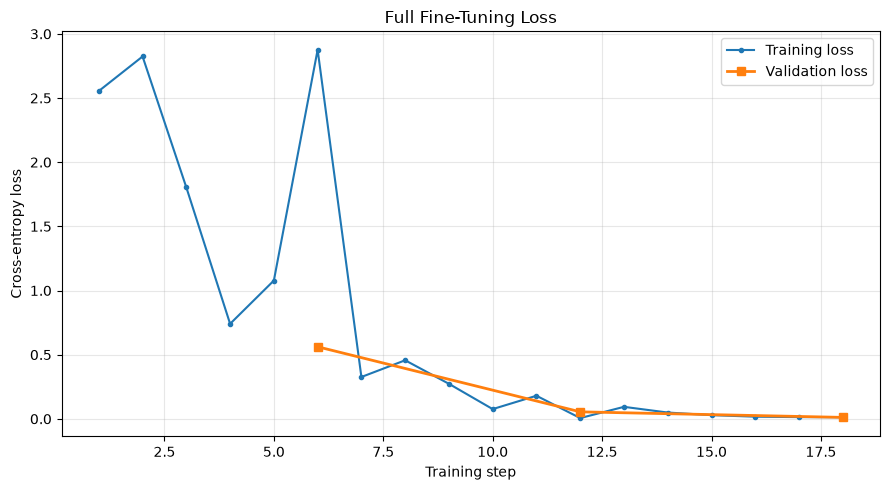

In [77]:
fig,ax=plt.subplots(figsize=(9,5))

if not train_logs.empty: ax.plot(train_logs["step"],train_logs["loss"],label="Training loss",marker="o",markersize=3)

if not eval_logs.empty: ax.plot(eval_logs["step"],eval_logs["eval_loss"],label="Validation loss",marker="s",linewidth=2)

ax.set(title="Full Fine-Tuning Loss",xlabel="Training step",ylabel="Cross-entropy loss")

ax.grid(alpha=.3); ax.legend(); plt.tight_layout()

plt.savefig(OUTPUT_DIR/"training_metrics.png",dpi=160); plt.show()

### How I Will Explain the Training Results



The charts must be interpreted from values produced by the completed local training run.



- **Training loss decreasing:** The model is fitting the demonstrations more effectively, but this alone does not prove groundedness or safety.

- **Validation loss decreasing:** Performance is improving on unseen validation examples from the same dataset design.

- **Training loss decreasing while validation loss increases:** This warns that the model may be memorizing the training style rather than generalizing.

- **Training and validation loss remaining high:** The dataset, model size, epoch count, or learning rate may be insufficient.

- **Irregular spikes:** A single spike is not automatically a failure; the broader trend and held-out responses matter more.



I will report the first and final training losses, best and final validation losses, and the relationship between both curves. I will not describe the model as successful solely because training completed.

*********

### Held-Out Base vs. Fine-Tuned Evaluation

Optimization metrics alone do not prove groundedness or safety. The notebook generates deterministic responses from the full fine-tuned checkpoint and the untouched Hugging Face base model for the same five held-out Milestone 2 capabilities. These exact prompts are excluded from training.

In [78]:
import gc



tests=[

(1,"Remote worker","Available plans: Connect 200 costs $45 with 200 Mbps download and 10 Mbps upload; Work 500 costs $70 with 500 Mbps download and 50 Mbps upload; Gig 1000 costs $95 with 1,000 Mbps download and 100 Mbps upload. A remote worker has ten devices and a $75 budget. Recommend one plan and one tradeoff without inventing terms."),

(2,"Bill increase","A bill increased from $80 to $100. A $20 promotional credit ended and no other charge changed. Explain it and give one next step."),

(3,"Family bundle","A family streams 4K on three TVs, has two gamers, uses 900 GB monthly, and wants to stay below $110. Family 500 is $85 with 1.2 TB; Family Gig is $105 with unlimited data; Premium Gig is $130 with unlimited data and equipment. Recommend one and explain the tradeoff."),

(4,"Proration","A customer upgraded on day 20 of a 30-day cycle. The bill has a credit for ten unused old-plan days and a charge for ten new-plan days. Explain without adding fees."),

(5,"Missing facts","My internet is slow. Tell me exactly which plan to buy. No speed test, device count, budget, current plan, or plan list is provided.")]



def generate_responses(model_to_use,model_type):

 model_to_use.eval(); model_device=next(model_to_use.parameters()).device; generated=[]

 for test_id,name,prompt in tests:

  messages=[{"role":"system","content":SYSTEM_PROMPT},{"role":"user","content":prompt}]

  text=tokenizer.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)

  inputs=tokenizer(text,return_tensors="pt").to(model_device)

  with torch.no_grad():

   output=model_to_use.generate(**inputs,max_new_tokens=300,do_sample=False,pad_token_id=tokenizer.pad_token_id)

  response=tokenizer.decode(output[0,inputs["input_ids"].shape[1]:],skip_special_tokens=True)

  generated.append({"id":test_id,"name":name,"model_type":model_type,"model":MODEL_NAME,"response":response})

 return generated



out=generate_responses(model,"fine_tuned")

del trainer, model; gc.collect()

if torch.cuda.is_available(): torch.cuda.empty_cache()



base_model=AutoModelForCausalLM.from_pretrained(MODEL_NAME,torch_dtype=torch.bfloat16 if use_bf16 else torch.float16 if DEVICE=="cuda" else torch.float32).to(DEVICE)

out.extend(generate_responses(base_model,"base"))

del base_model; gc.collect()

if torch.cuda.is_available(): torch.cuda.empty_cache()



comparison=pd.DataFrame(out).sort_values(["id","model_type"])

comparison.to_csv(OUTPUT_DIR/"held_out_responses.csv",index=False); display(comparison)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

,id,name,model_type,model,response
5,1,Remote worker,base,Qwen/Qwen2.5-0.5B-Instruct,Recommend Gigabit (Gig 1000) as it offers the ...
0,1,Remote worker,fine_tuned,Qwen/Qwen2.5-0.5B-Instruct,Customer need\nThe employee has ten devices wi...
6,2,Bill increase,base,Qwen/Qwen2.5-0.5B-Instruct,The increase in the bill from $80 to $100 indi...
1,2,Bill increase,fine_tuned,Qwen/Qwen2.5-0.5B-Instruct,Customer need\nThe customer wants to understan...
7,3,Family bundle,base,Qwen/Qwen2.5-0.5B-Instruct,### Recommendation\n\n**Recommendation:** \nFo...
2,3,Family bundle,fine_tuned,Qwen/Qwen2.5-0.5B-Instruct,Customer need\nThe customer has 900GB of month...
8,4,Proration,base,Qwen/Qwen2.5-0.5B-Instruct,### Explanation\n\nThe customer's upgrade to a...
3,4,Proration,fine_tuned,Qwen/Qwen2.5-0.5B-Instruct,Customer need\nThe customer wants to understan...
9,5,Missing facts,base,Qwen/Qwen2.5-0.5B-Instruct,To determine the best plan for your internet s...
4,5,Missing facts,fine_tuned,Qwen/Qwen2.5-0.5B-Instruct,"Customer need\nGuidance is requested, but veri..."


### Human Rubric
Score each response from 1 to 5 for groundedness, relevance, clarity, completeness, and safety. Scores are intentionally blank until the generated responses are reviewed. This prevents expected performance from being presented as observed evidence.

In [84]:
criteria=["groundedness","relevance","clarity","completeness","safety"]

score_path=OUTPUT_DIR/"human_scoring_template.csv"

score_keys=["id","model_type"]

scoring=comparison.copy()



if score_path.exists():

 prior=pd.read_csv(score_path)

 available=[column for column in criteria+["review_notes"] if column in prior.columns]

 scoring=scoring.merge(prior[score_keys+available],on=score_keys,how="left")

else:

 for criterion in criteria: scoring[criterion]=pd.NA

 scoring["review_notes"]=""



for criterion in criteria:

 if criterion not in scoring: scoring[criterion]=pd.NA

if "review_notes" not in scoring: scoring["review_notes"]=""

scoring.to_csv(score_path,index=False)

print("Human scoring file:",score_path)

display(scoring[["id","name","model_type","response"]+criteria+["review_notes"]])

Human scoring file: milestone3_outputs/human_scoring_template.csv


,id,name,model_type,response,groundedness,relevance,clarity,completeness,safety,review_notes
0,1,Remote worker,base,Recommend Gigabit (Gig 1000) as it offers the ...,1,3,3,2,2,Recommends the $95 plan despite the $75 limit ...
1,1,Remote worker,fine_tuned,Customer need\nThe employee has ten devices wi...,2,4,5,4,2,Uses the required structure but incorrectly ca...
2,2,Bill increase,base,The increase in the bill from $80 to $100 indi...,1,2,3,2,2,Ignores the confirmed ended credit and adds un...
3,2,Bill increase,fine_tuned,Customer need\nThe customer wants to understan...,4,4,5,4,5,Correctly explains the $20 change without spec...
4,3,Family bundle,base,### Recommendation\n\n**Recommendation:** \nFo...,1,3,3,2,2,Chooses the $130 option above budget and inven...
5,3,Family bundle,fine_tuned,Customer need\nThe customer has 900GB of month...,2,4,4,3,3,Selects the eligible $105 option but renames i...
6,4,Proration,base,### Explanation\n\nThe customer's upgrade to a...,2,3,4,2,2,Partially recognizes ten new-plan days but omi...
7,4,Proration,fine_tuned,Customer need\nThe customer wants to understan...,2,1,4,1,3,Avoids a fabricated fee but does not explain e...
8,5,Missing facts,base,To determine the best plan for your internet s...,2,4,3,2,3,Requests useful facts but invents generic plan...
9,5,Missing facts,fine_tuned,"Customer need\nGuidance is requested, but veri...",5,5,5,5,5,Correctly refuses to guess and requests the mi...


,groundedness,relevance,clarity,completeness,safety,overall
model_type,,,,,,
base,1.4,3.0,3.2,2.0,2.2,2.36
fine_tuned,3.0,3.6,4.6,3.4,3.6,3.64


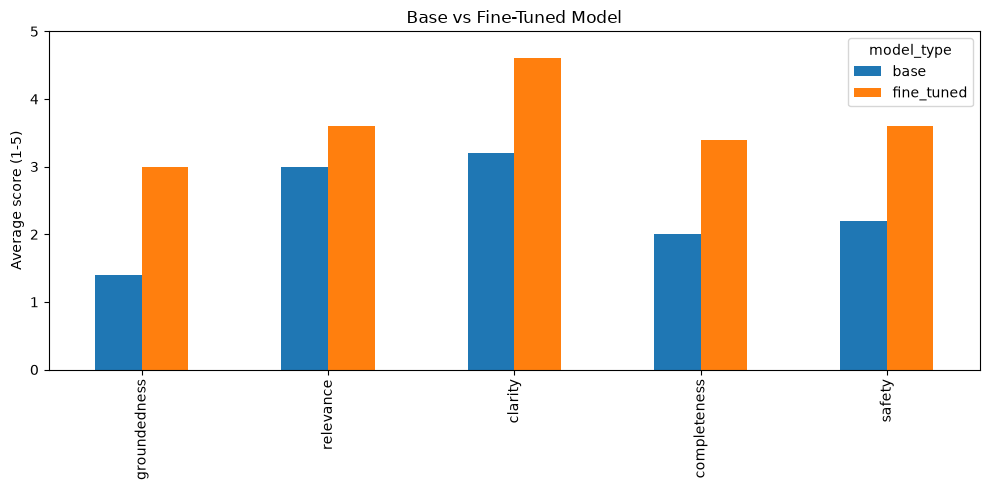

In [85]:
scored=pd.read_csv(score_path)

for criterion in criteria: scored[criterion]=pd.to_numeric(scored[criterion],errors="coerce")



invalid_mask=scored[criteria].notna() & ~scored[criteria].apply(lambda column: column.between(1,5))

if invalid_mask.any().any():

 invalid_columns=invalid_mask.stack()[lambda values: values].index.tolist()

 raise ValueError(f"Rubric scores must be between 1 and 5. Invalid cells: {invalid_columns}")



missing_mask=scored[criteria].isna().any(axis=1)

SCORING_COMPLETE=not missing_mask.any()

summary=pd.DataFrame()



if not SCORING_COMPLETE:

 print(f"Human review pending: {missing_mask.sum()} of {len(scored)} responses still need complete 1-5 scores.")

 print("Enter ratings in",score_path,"and rerun this cell.")

 display(scored.loc[missing_mask,["id","name","model_type"]+criteria])

else:

 scored["overall"]=scored[criteria].mean(axis=1)

 summary=scored.groupby("model_type")[criteria+["overall"]].mean().round(2)

 display(summary); summary.to_csv(OUTPUT_DIR/"held_out_score_summary.csv")

 ax=summary[criteria].T.plot(kind="bar",figsize=(10,5),ylim=(0,5),title="Base vs Fine-Tuned Model")

 ax.set_ylabel("Average score (1-5)"); plt.tight_layout()

 plt.savefig(OUTPUT_DIR/"held_out_comparison.png",dpi=160); plt.show()

### Additional Result Visualizations

The grouped bar chart provides an overall comparison by evaluation criterion. The next visualizations add two perspectives:

1. A **scenario-level heatmap** shows where each model succeeds or fails across the five held-out tasks. This prevents a strong result on one easy scenario from hiding a weakness in billing or missing-information handling.
2. An **improvement chart** subtracts the base-model average from the fine-tuned-model average for each criterion. Positive values favor the fine-tuned model; negative values indicate regression.

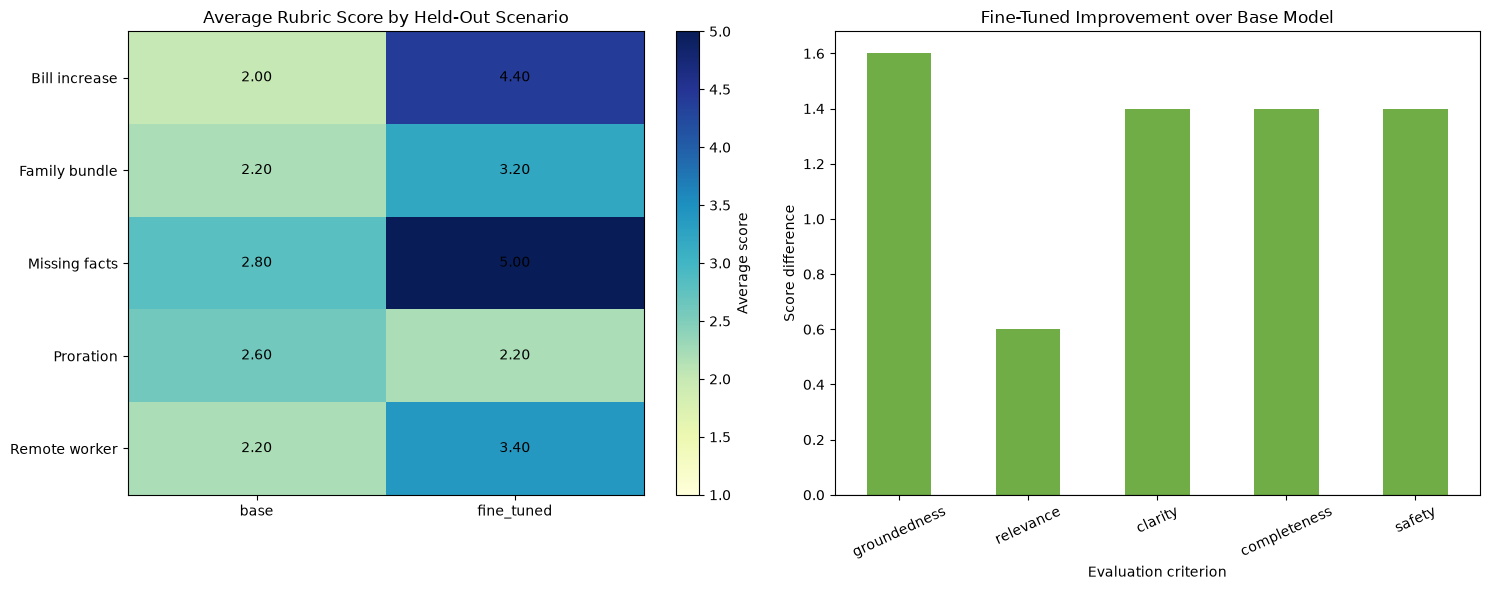

In [86]:
if not SCORING_COMPLETE:

 print("Scenario and improvement charts skipped until human scoring is complete.")

else:

 scenario_scores=scored.groupby(["name","model_type"])[criteria].mean().mean(axis=1).unstack("model_type")

 criterion_delta=summary.loc["fine_tuned",criteria]-summary.loc["base",criteria]

 fig,ax=plt.subplots(1,2,figsize=(15,6))

 im=ax[0].imshow(scenario_scores.values,aspect="auto",cmap="YlGnBu",vmin=1,vmax=5)

 ax[0].set_xticks(range(len(scenario_scores.columns)),scenario_scores.columns)

 ax[0].set_yticks(range(len(scenario_scores.index)),scenario_scores.index)

 ax[0].set_title("Average Rubric Score by Held-Out Scenario")

 for row_index in range(scenario_scores.shape[0]):

  for column_index in range(scenario_scores.shape[1]):

   ax[0].text(column_index,row_index,f"{scenario_scores.iloc[row_index,column_index]:.2f}",ha="center",va="center")

 plt.colorbar(im,ax=ax[0],label="Average score")

 colors=["#70AD47" if value>=0 else "#C00000" for value in criterion_delta]

 criterion_delta.plot(kind="bar",ax=ax[1],color=colors)

 ax[1].axhline(0,color="black",linewidth=.8)

 ax[1].set(title="Fine-Tuned Improvement over Base Model",xlabel="Evaluation criterion",ylabel="Score difference")

 ax[1].tick_params(axis="x",rotation=25)

 plt.tight_layout(); plt.savefig(OUTPUT_DIR/"scenario_and_improvement_analysis.png",dpi=160); plt.show()

**How I will interpret these charts:** 

* A convincing result should show improvement across several scenarios, especially the billing and insufficient-information tests that were weak or important in Milestone 2. 
* Improvement in clarity alone is not enough if groundedness or safety declines. 
* If a negative bar for safety or groundedness then it would require investigation even if the overall average increased.

*******

### Commentary: Did Fine-Tuning Work?



### Dataset Result



After removing 27 duplicate prompts, the corpus contained 53 unique examples. The stratified split produced 42 training records and 11 validation records with no prompt leakage. The source and response-length charts confirmed representation of plan recommendation, billing, missing-information, and rewritten public-question behaviors.



### Build Result



Full-parameter supervised fine-tuning completed successfully for `Qwen/Qwen2.5-0.5B-Instruct` on the Apple MPS device. All **494,032,768 of 494,032,768 parameters (100%)** were trainable, confirming that the run did not use LoRA, adapters, or frozen layers. Training ran for **3 epochs**, required **118.74 seconds**, processed **1.061 samples per second**, and saved the complete model to `milestone3_outputs/qwen_full_finetune`.



### Optimization Result



The logged training loss decreased from **2.5547** at the first step to **0.0128** at the final step. Validation loss decreased at every epoch, from **0.5616** after epoch 1 to **0.0546** after epoch 2 and **0.0113** after epoch 3. The validation curve did not diverge from the training curve, so this run contains no direct loss-based sign of overfitting. However, the extremely low losses must be interpreted cautiously because the dataset is small and uses highly consistent synthetic response templates.



### Held-Out Behavioral Result



The fine-tuned model's average rubric score was **3.64**, compared with **2.36** for the base model, an improvement of **1.28 points**. Average criterion scores changed as follows:



- **Groundedness:** 1.40 to 3.00 (**+1.60**)

- **Relevance:** 3.00 to 3.60 (**+0.60**)

- **Clarity:** 3.20 to 4.60 (**+1.40**)

- **Completeness:** 2.00 to 3.40 (**+1.40**)

- **Safety:** 2.20 to 3.60 (**+1.40**)



Scenario-level averages provide a more qualified result:



1. **Remote worker:** 2.20 to 3.40. Structure and clarity improved, but the tuned model still recommended the $95 plan despite the $75 budget.

2. **Bill increase:** 2.00 to 4.40. The tuned model correctly connected the $20 increase to the listed item and avoided unsupported causes, although it did not explicitly repeat that the promotional credit ended.

3. **Family bundle:** 2.20 to 3.20. The tuned model selected the eligible $105 option but renamed the plan and incorrectly changed unlimited data to 1 TB.

4. **Proration:** 2.60 to 2.20. This was the only regression; the tuned response failed to explain the old-plan credit and new-plan charge.

5. **Missing facts:** 2.80 to 5.00. The tuned model correctly refused to guess and requested the relevant plan, usage, device, and budget facts.



### Final Judgment



Full fine-tuning improved the intended response structure, restraint, clarity, and average groundedness, so the experiment was successful as a controlled proof of concept. It was not uniformly successful: the budget violation, altered data allowance, and proration regression show that the checkpoint is not ready for production use. The next iteration should add more diverse counterexamples for strict budget filtering, exact plan-attribute copying, and proration explanations before retraining.

******

### Responsible AI and Limitations



The experiment excludes real customer records, identifiers, account activity, and proprietary policies. Public questions were used only as scenario seeds, and their target answers were rewritten to avoid unsupported provider claims. The system prompt also prohibits invented prices, fees, promotions, taxes, policies, availability, and guarantees.



The evidence still has important limitations. The corpus contained only **53 unique examples**, with **42 used for training** and **11 for validation**. Many targets share the same five-part template, and the synthetic examples are cleaner than real customer conversations. Consequently, the final validation loss of **0.0113** may reflect strong fit to this narrow data-generating pattern rather than broad telecom-support generalization. The held-out set included only five scenarios, and the 1–5 rubric was completed by one reviewer, so the scores are subjective and do not provide statistical confidence.



The fine-tuned model improved from **2.36 to 3.64 overall**, but it still recommended a plan above budget, changed an unlimited allowance to 1 TB, and regressed on proration. These are consequential factual failures. A production assistant would require a larger and more diverse evaluation set, multiple independent reviewers, retrieval of approved current plan facts, automated checks for numerical constraints, and human escalation for billing disputes, credits, exceptions, or account changes.

********

### Conclusion



This milestone completed full-parameter supervised fine-tuning of `Qwen/Qwen2.5-0.5B-Instruct` without LoRA or adapters. The run updated **100% of the model's 494,032,768 parameters** for **3 epochs**, reduced training loss from **2.5547 to 0.0128**, reduced validation loss from **0.5616 to 0.0113**, and saved the complete checkpoint locally.



Held-out human evaluation found that the fine-tuned model improved from **2.36 to 3.64 overall**. The largest criterion gain was groundedness at **+1.60 points**, and the strongest scenario was missing-information handling at **5.00**. These results support the conclusion that full fine-tuning successfully taught the desired response structure and more conservative behavior. The conclusion remains qualified because the model violated a budget constraint, altered a supplied data allowance, and scored **2.20** on proration compared with the base model's **2.60**. The checkpoint is therefore a successful academic proof of concept, not a production-ready telecom assistant.

********

## References



Hugging Face. (n.d.). *Transformers Trainer*. https://huggingface.co/docs/transformers/main_classes/trainer  

Hugging Face. (n.d.). *Qwen2.5-0.5B-Instruct*. https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct  

Akshay Jambhulkar. (n.d.). *Customer-support-telecom-alpaca* [Data set]. Hugging Face. https://huggingface.co/datasets/akshayjambhulkar/customer-support-telecom-alpaca  

Vaswani, A., et al. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*.